# Distance, rainfall, and delivery delay analysis

Objective: examine how distance and rainfall relate to **late-delivery rates** and **delay duration among late orders**, providing exploratory evidence for a subsequent regression experiment.

This analysis uses **only Train from the existing split manifest**. Results are descriptive and do not establish causality or predictive feature importance. Group boundaries were chosen for interpretation and are not optimized alert thresholds.

- Late-delivery rate = late orders / all orders with a valid feature value in the group.
- Delay days = actual delivery date − estimated delivery date, using calendar dates.
- Delay medians, means, and percentiles are computed only for orders with is_late = 1.
- Rainfall represents state-level observations from the previous complete UTC day before purchase under assume_utc. These features describe weather near purchase time; they do not cover subsequent transit days.

Tables are exported to `outputs/tables/delay_prediction/factor_analysis` and figures to `outputs/figures/delay_prediction`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/ml_preparation/split_manifest.csv').exists())
TABLES = ROOT / 'outputs/tables/delay_prediction/factor_analysis'
FIGURES = ROOT / 'outputs/figures/delay_prediction'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
FEATURES = ['distance_km_mean', 'destination_rain_state_mean_mm',
            'origin_rain_state_mean_mm']

## 1. Merge data and validate outcomes

Check unique order IDs, Train counts, date completeness, and consistency between late labels and delay duration. The existing Train split includes only orders delivered before April 16, 2018. Long-delayed orders whose outcomes were unavailable at that cutoff may be excluded by the split rules; consider this limitation when interpreting delay severity.

In [2]:
columns = ['order_id', 'is_late', 'delivery_delay_days',
           'order_delivered_customer_date', 'order_estimated_delivery_date',
           'estimated_window_days', 'customer_state', *FEATURES]
data = pd.read_csv(ROOT / 'data/processed/research_data_weather_price_holiday_assume_utc.csv',
                   usecols=columns)
manifest = pd.read_csv(ROOT / 'data/ml_preparation/split_manifest.csv')
assert data.order_id.is_unique and manifest.order_id.is_unique
train_ids = manifest.loc[manifest['split'].eq('train'), ['order_id', 'purchase_time']]
train = train_ids.merge(data, on='order_id', how='left', validate='one_to_one', indicator=True)
assert train['_merge'].eq('both').all()
assert len(train) == 57449 and train.is_late.sum() == 3720
assert train.is_late.isin([0, 1]).all()
actual = pd.to_datetime(train.order_delivered_customer_date)
estimated = pd.to_datetime(train.order_estimated_delivery_date)
purchase = pd.to_datetime(train.purchase_time)
delay = (actual.dt.normalize() - estimated.dt.normalize()).dt.days
assert actual.notna().all() and estimated.notna().all()
assert actual.lt(pd.Timestamp('2018-04-16')).all()
assert purchase.lt(pd.Timestamp('2018-03-02')).all()
assert actual.ge(purchase).all()
np.testing.assert_array_equal(delay.to_numpy(), train.delivery_delay_days.to_numpy())
np.testing.assert_array_equal(delay.gt(0).astype(int), train.is_late.astype(int))
assert train[FEATURES].ge(0).where(train[FEATURES].notna(), True).all().all()
assert np.isfinite(train[FEATURES].stack()).all()
late = train.loc[train.is_late.eq(1)].copy()
audit = pd.DataFrame([{
    'orders': len(train), 'late_orders': len(late),
    'late_rate_pct': 100 * train.is_late.mean(),
    'late_delay_median_days': late.delivery_delay_days.median(),
    'late_delay_mean_days': late.delivery_delay_days.mean(),
    'late_delay_p90_days': late.delivery_delay_days.quantile(.9),
}])
audit.to_csv(TABLES / 'train_audit.csv', index=False)
display(audit.round(3))
coverage = pd.DataFrame([{
    'feature': feature, 'valid_orders': train[feature].notna().sum(),
    'missing_orders': train[feature].isna().sum(),
    'missing_late_orders': train.loc[train[feature].isna(), 'is_late'].sum(),
} for feature in FEATURES])
coverage.to_csv(TABLES / 'feature_coverage.csv', index=False)
display(coverage)

,orders,late_orders,late_rate_pct,late_delay_median_days,late_delay_mean_days,late_delay_p90_days
0,57449,3720,6.475,7.0,10.736,22.0


,feature,valid_orders,missing_orders,missing_late_orders
0,distance_km_mean,57149,300,25.0
1,destination_rain_state_mean_mm,56850,599,46.0
2,origin_rain_state_mean_mm,57332,117,5.0


## 2. Group summaries

Distance groups: ≤100, >100–300, >300–600, >600–1,000, >1,000–2,000, and >2,000 km. Rainfall groups: 0, >0–5, >5–10, >10–20, and >20 mm. Groups do not overlap.

Missing feature values are reported separately in the coverage table and excluded from that feature's grouped analysis. The 90th percentile is the delay level at or below which 90% of late orders in the group fall. Median promised delivery windows and distances provide context for differences in order composition across groups.

In [3]:
def summarize_groups(frame, groups):
    work = frame.assign(group=groups)
    summary = work.groupby('group', observed=True).agg(
        orders=('is_late', 'size'), late_orders=('is_late', 'sum'),
        late_rate=('is_late', 'mean'),
        distance_median_km=('distance_km_mean', 'median'),
        estimated_window_median_days=('estimated_window_days', 'median'))
    delays = work.loc[work.is_late.eq(1)].groupby('group', observed=True).delivery_delay_days
    severity = delays.agg(delay_median_days='median', delay_mean_days='mean',
                          delay_p25_days=lambda x: x.quantile(.25),
                          delay_p75_days=lambda x: x.quantile(.75),
                          delay_p90_days=lambda x: x.quantile(.9))
    summary['late_rate_pct'] = summary.pop('late_rate') * 100
    summary['late_orders'] = summary.late_orders.astype(int)
    return summary.join(severity)

specs = {
    'distance_km_mean': ([-np.inf, 100, 300, 600, 1000, 2000, np.inf],
        ['≤100', '>100–300', '>300–600', '>600–1000', '>1000–2000', '>2000'],
        'Seller-to-customer distance (km)'),
    'destination_rain_state_mean_mm': ([-np.inf, 0, 5, 10, 20, np.inf],
        ['0', '>0–5', '>5–10', '>10–20', '>20'], 'Destination rain (mm)'),
    'origin_rain_state_mean_mm': ([-np.inf, 0, 5, 10, 20, np.inf],
        ['0', '>0–5', '>5–10', '>10–20', '>20'], 'Origin rain (mm)'),
}
summaries = {}
for feature, (edges, labels, title) in specs.items():
    groups = pd.cut(train[feature], edges, labels=labels)
    summary = summarize_groups(train, groups)
    assert summary.orders.sum() == train[feature].notna().sum()
    summaries[feature] = summary
    summary.to_csv(TABLES / f'{feature}_groups.csv', index_label='group')
    print(title)
    display(summary.round(3))

Seller-to-customer distance (km)


,orders,late_orders,distance_median_km,estimated_window_median_days,late_rate_pct,delay_median_days,delay_mean_days,delay_p25_days,delay_p75_days,delay_p90_days
group,,,,,,,,,,
≤100,9606,362,31.172,16.0,3.768,5.0,9.199,2.0,9.0,16.9
>100–300,7804,388,201.196,22.0,4.972,6.0,9.247,3.0,13.0,20.0
>300–600,19114,1289,424.096,24.0,6.744,7.0,10.377,3.0,14.0,22.0
>600–1000,11104,764,790.347,27.0,6.880,7.0,10.603,3.0,14.0,22.0
>1000–2000,6092,545,1357.008,31.0,8.946,7.0,11.976,3.0,14.0,22.0
>2000,3429,347,2280.040,35.0,10.120,8.0,13.608,4.0,13.0,24.4


Destination rain (mm)


,orders,late_orders,distance_median_km,estimated_window_median_days,late_rate_pct,delay_median_days,delay_mean_days,delay_p25_days,delay_p75_days,delay_p90_days
group,,,,,,,,,,
0,2947,167,835.877,27.0,5.667,8.0,12.317,4.5,15.0,23.4
>0–5,37116,2285,444.362,24.0,6.156,7.0,10.942,3.0,13.0,23.0
>5–10,8381,617,409.305,25.0,7.362,7.0,10.237,3.0,13.0,20.0
>10–20,6275,456,402.184,25.0,7.267,7.0,10.221,3.0,14.0,21.0
>20,2131,149,444.968,25.0,6.992,6.0,10.409,3.0,12.0,21.2


Origin rain (mm)


,orders,late_orders,distance_median_km,estimated_window_median_days,late_rate_pct,delay_median_days,delay_mean_days,delay_p25_days,delay_p75_days,delay_p90_days
group,,,,,,,,,,
0,1223,62,627.645,25.0,5.070,7.0,11.194,4.0,16.0,24.9
>0–5,38087,2299,454.952,25.0,6.036,7.0,11.185,3.0,13.0,22.0
>5–10,9104,735,427.541,25.0,8.073,7.0,9.382,3.0,13.0,20.0
>10–20,6813,483,435.539,26.0,7.089,7.0,10.356,3.0,14.0,21.8
>20,2105,136,471.065,25.0,6.461,7.5,11.375,3.0,14.0,22.0


## 3. Late-delivery rate and delay severity plots

The left panel uses all orders with valid feature values. The right panel uses only late orders and shows the median and the 25th–75th percentile range to describe dispersion. This range describes the observed data; it is not a confidence interval for the median.

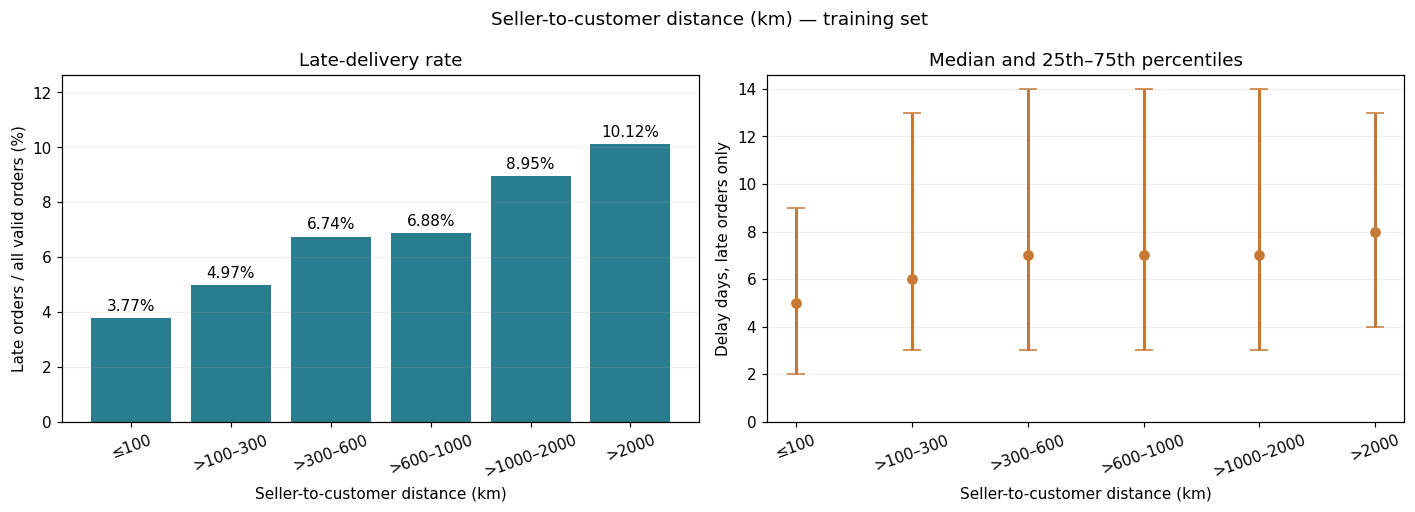

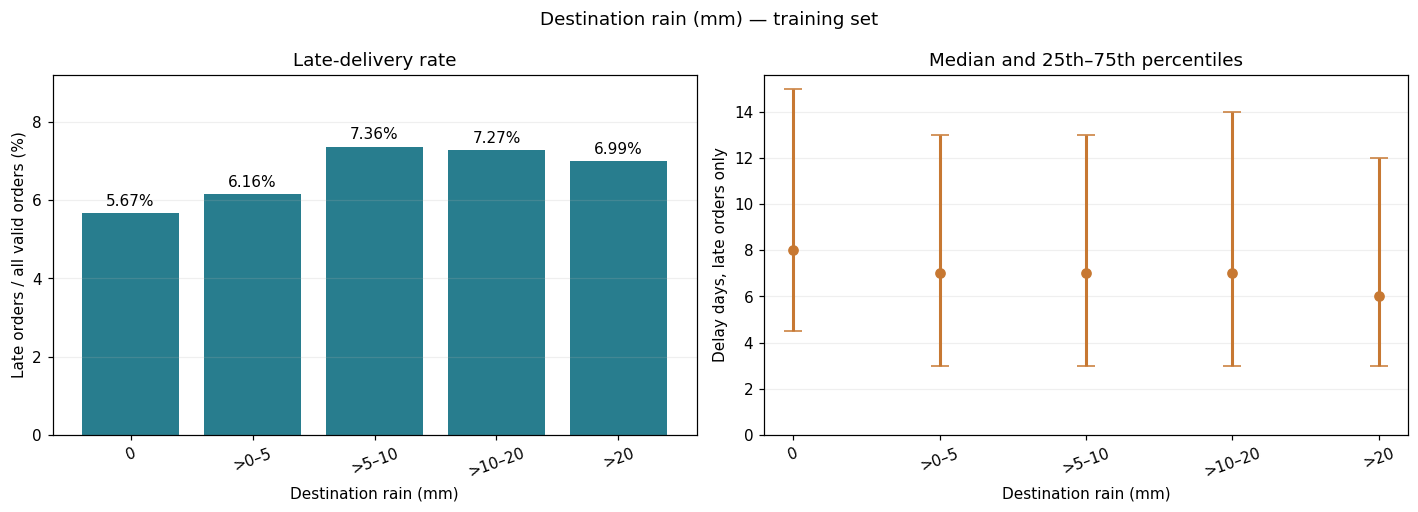

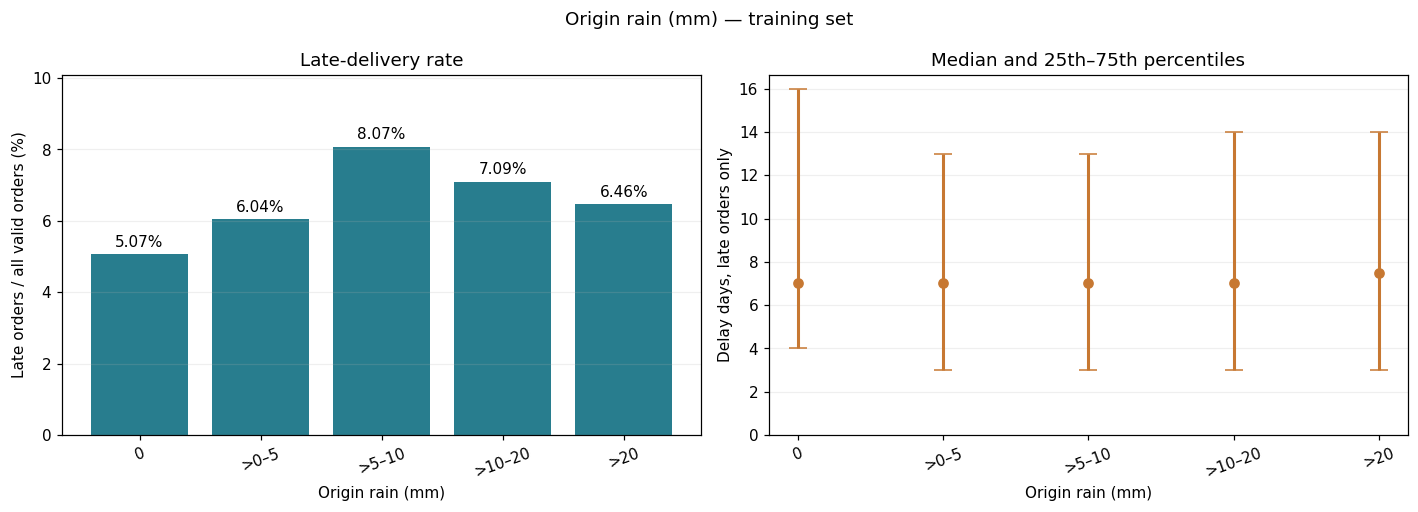

In [4]:
for feature, summary in summaries.items():
    title = specs[feature][2]
    positions = np.arange(len(summary))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
    bars = axes[0].bar(positions, summary.late_rate_pct, color='#287d8e')
    axes[0].bar_label(bars, labels=[f'{v:.2f}%' for v in summary.late_rate_pct], padding=3)
    axes[0].set_ylim(0, summary.late_rate_pct.max() * 1.25)
    axes[0].set_ylabel('Late orders / all valid orders (%)')
    axes[0].set_title('Late-delivery rate')
    median = summary.delay_median_days
    axes[1].errorbar(positions, median,
        yerr=[median-summary.delay_p25_days, summary.delay_p75_days-median],
        fmt='o', capsize=6, color='#c77832', linewidth=2)
    axes[1].set_ylim(bottom=0)
    axes[1].set_ylabel('Delay days, late orders only')
    axes[1].set_title('Median and 25th–75th percentiles')
    for ax in axes:
        ax.set_xticks(positions, summary.index.astype(str), rotation=20)
        ax.set_xlabel(title)
        ax.grid(axis='y', alpha=.2)
    fig.suptitle(title + ' — training set')
    fig.tight_layout()
    fig.savefig(FIGURES / f'{feature}_rate_and_severity.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 4. Correlation with delay duration and rainfall by distance group

Spearman correlation measures monotonic association on a scale from −1 to 1. Values close to zero indicate weak marginal monotonic association; a model may still learn nonlinear relationships or interactions. These coefficients are not predictive feature-importance scores.

Rainfall × distance tables help examine differences in order composition. Interpret cells containing few late orders cautiously. This grouping does not fully adjust for destination state, season, or the estimated delivery window.

In [5]:
correlations = pd.DataFrame([{
    'feature': feature,
    'late_orders_with_value': late[feature].notna().sum(),
    'spearman_with_delay_late_only': late[[feature, 'delivery_delay_days']].corr(method='spearman').iloc[0, 1],
} for feature in FEATURES])
correlations.to_csv(TABLES / 'late_only_spearman.csv', index=False)
display(correlations.round(4))

distance_group = pd.cut(train.distance_km_mean, [-np.inf, 300, 1000, np.inf],
                        labels=['≤300 km', '>300–1000 km', '>1000 km'])
for feature in FEATURES[1:]:
    rain_group = pd.cut(train[feature], [-np.inf, 5, np.inf], labels=['≤5 mm', '>5 mm'])
    work = train.assign(distance_group=distance_group, rain_group=rain_group)
    cross = work.groupby(['distance_group', 'rain_group'], observed=True).agg(
        orders=('is_late', 'size'), late_orders=('is_late', 'sum'),
        late_rate_pct=('is_late', lambda x: 100*x.mean()))
    severity = work.loc[work.is_late.eq(1)].groupby(
        ['distance_group', 'rain_group'], observed=True).delivery_delay_days.median()
    cross['delay_median_days_late_only'] = severity
    cross.to_csv(TABLES / f'{feature}_by_distance.csv')
    print(specs[feature][2], 'by distance')
    display(cross.round(3))

,feature,late_orders_with_value,spearman_with_delay_late_only
0,distance_km_mean,3695,0.0841
1,destination_rain_state_mean_mm,3674,-0.0094
2,origin_rain_state_mean_mm,3715,-0.0010


Destination rain (mm) by distance


orders  late_orders  late_rate_pct  \
distance_group rain_group                                       
≤300 km        ≤5 mm        11710        481.0          4.108   
               >5 mm         5686        268.0          4.713   
>300–1000 km   ≤5 mm        21015       1291.0          6.143   
               >5 mm         8939        740.0          8.278   
>1000 km       ≤5 mm         7137        662.0          9.276   
               >5 mm         2082        207.0          9.942   

                           delay_median_days_late_only  
distance_group rain_group                               
≤300 km        ≤5 mm                               6.0  
               >5 mm                               5.0  
>300–1000 km   ≤5 mm                               7.0  
               >5 mm                               7.0  
>1000 km       ≤5 mm                               7.0  
               >5 mm                               7.0

Origin rain (mm) by distance


orders  late_orders  late_rate_pct  \
distance_group rain_group                                       
≤300 km        ≤5 mm        11673        486.0          4.163   
               >5 mm         5726        263.0          4.593   
>300–1000 km   ≤5 mm        20790       1273.0          6.123   
               >5 mm         9363        780.0          8.331   
>1000 km       ≤5 mm         6659        588.0          8.830   
               >5 mm         2828        300.0         10.608   

                           delay_median_days_late_only  
distance_group rain_group                               
≤300 km        ≤5 mm                               5.5  
               >5 mm                               5.0  
>300–1000 km   ≤5 mm                               7.0  
               >5 mm                               7.0  
>1000 km       ≤5 mm                               7.0  
               >5 mm                               7.0

## 5. Interpretation of the current run

The statements below use values calculated directly from the summary tables. First-to-last group comparisons are descriptive and should be read alongside the complete tables and plots.

In [6]:
from IPython.display import Markdown
distance = summaries['distance_km_mean']
first, last = distance.iloc[0], distance.iloc[-1]
lines = [
    f'- **Distance:** the late-delivery rate ranges from {first.late_rate_pct:.2f}% '
    f'in the ≤100 km group to {last.late_rate_pct:.2f}% in the >2000 km group. '
    f'The corresponding median delays among late orders are '
    f'{first.delay_median_days:g} and {last.delay_median_days:g} days.',
]
for feature in FEATURES[1:]:
    row = correlations.loc[correlations.feature.eq(feature)].iloc[0]
    lines.append(f'- **{specs[feature][2]}:** Spearman correlation with delay duration '
                 f'among late orders = {row.spearman_with_delay_late_only:.4f}.')
display(Markdown('\n'.join(lines)))

- **Distance:** the late-delivery rate ranges from 3.77% in the ≤100 km group to 10.12% in the >2000 km group. The corresponding median delays among late orders are 5 and 8 days.
- **Destination rain (mm):** Spearman correlation with delay duration among late orders = -0.0094.
- **Origin rain (mm):** Spearman correlation with delay duration among late orders = -0.0010.

### What could the model learn?

- **Distance:** group differences provide a signal about late-delivery risk. Delay duration remains widely dispersed, so distance alone is insufficient for precise day-level predictions.
- **Rainfall:** examine both late rates and delay severity. Differences in late rates may also reflect geography and season. Pre-purchase rainfall has limited coverage of weather conditions during multi-day transit.
- **Combined features:** distance, the estimated delivery window, destination state, and product characteristics may provide complementary information. Predictive usefulness must be evaluated on validation data.

### Next step

Train a regression model using all 21 features on late orders in Train. Compare its MAE against a baseline that always predicts the median Train delay. Validation A will establish whether the model improves on that baseline. This notebook does not establish causal relationships or the benefits of an operational intervention.

Definition sources: `docs/predictor_list.csv`, `docs/data_preprocessing/order_dataset_dictionary.md`, `docs/data_preprocessing/enriched_features_dictionary.md`, and `docs/data_preprocessing/temporal_features_dictionary.md`.